# 08 · The NIR workflow: SNNs trained elsewhere

Every notebook so far built its network **by hand** with `snn.Population` and `snn.Projection`.
But if we want to import a network that was already designed and trained in a framework like
[snnTorch](https://github.com/jeshraghian/snntorch), [Norse](https://github.com/norse/norse), or
[Sinabs](https://github.com/synsense/sinabs) we can use **Neuromorphic Intermediate Representation (NIR)**
to import those already-made models onto SpiNNaker2.

**By the end you'll know:**

- what a NIR graph is, 
- how to export a model from snnTorch (`export_to_nir`) or load a saved one (`nir.read`),
- how to convert it into a py-spinnaker2 network with [`s2_nir.from_nir`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/s2_nir-api.html),
- what each `ConversionConfig` setting does,
- which NIR primitives map to which SpiNNaker2 neuron models,
- what changes when you scale up to larger, trained models.

> **Info**
>
> This whole notebook runs on the **Brian2 simulator** — no board required. We use a small **snnTorch** network as the running example; it's left untrained (training is snnTorch's job, and is shown end-to-end in the notebooks linked in Section 4) so we can focus on the conversion, which is identical whether or not the model is trained.

## 1. What NIR is — train once, deploy anywhere

NIR is a **framework-neutral description of an SNN**: a graph whose nodes are computational primitives —
groups of neurons (`LIF`, `CubaLIF`, …) and the weight matrices that link them (`Linear`, `Affine`,
`Conv2d`, …) — with edges carrying each node's output to the next. It captures everything needed to
*run* the model.

That neutrality is the point. You design and validate once and deploy anywhere:

<img src="images/nir_pipeline.svg"  style="max-width:50%;height:auto" alt="NIR pipeline">

Your design framework defines the model and exports it to the portable `.nir` file. **py-spinnaker2
picks it up from `nir.read` onward** — that's the part this notebook covers.

The NIR graph represents a spiking neural network. For example, a conventional `ANN` can be converted to an `SNN` through `ANN-to-SNN` conversion in the training framework before export. Regardless of how the network was obtained, it is exported to the same `.nir` format and deployed through py-spinnaker2's `s2_nir.from_nir` in exactly the same way. From the perspective of `py-spinnaker2`, the network's origin is irrelevant.

## 2. Supported NIR primitives & neuron mapping

`s2_nir.from_nir` knows how to translate this set of NIR primitives:

| NIR primitive | py-spinnaker2 |
|:--------------|:--------------|
| `IF`        | `lif` with leakage disabled |
| `LIF`       | `lif` |
| `CubaLIF`   | `lif_curr_exp` |
| `Input`     | `spike_list` population |
| `Output`    | enables recording on the preceding node |
| `Linear`    | Projection |
| `Affine`    | Projection + `i_offset` bias in the target population |
| `Conv2d`    | `Conv2dProjection` |
| `Flatten`   | merged into the following Projection |
| `SumPool2d` | fused into the next connection — `Projection` (before a neuron, or a Flatten→Affine) or `Conv2dProjection` (before a `Conv2d`); requires stride == kernel size |

A NIR graph describes neurons in **continuous time**: a `LIF` node carries physical constants like the
membrane time constant `tau`, a resistance `r`, and a threshold, and its dynamics are a differential
equation. The SpiNNaker2 chip, on the other hand, advances in **discrete steps** and has no notion of
`tau` — each neuron just multiplies its state by a per-step **decay factor** every timestep. So the
translation (`nir.LIF` → `lif`, `nir.CubaLIF` → `lif_curr_exp`) is a bit of algebra that turns each
continuous-time `tau` into a decay factor for the chosen timestep `dt` (e.g. `1 - dt/tau` for
`FORWARD`, `exp(-dt/tau)` for `EXPONENTIAL`) and rescales resistance and threshold to match. This is
where `cfg.dt` and `cfg.integrator` come in — they define *how* that continuous → discrete conversion
is done (Section 3.3). You don't need to do it by hand — but if you want the exact formulas for each
`integrator` choice, they're in the
[NIR user guide](https://spinnaker2.gitlab.io/py-spinnaker2/user_guide/qs-nir.html#neuron-model-translation).

In [1]:
!pip3 install -q snntorch==0.9.4 nirtorch==2.0.2 numpy==2.3.4 nir==1.0.4

## 3. A minimal NIR example

Time to see the whole pipeline end to end. We take one small snnTorch network all the way onto py-spinnaker2 — pick a backend, build and export the model, convert it with `s2_nir.from_nir`, feed it input, and read the result back.

### 3.1 Backend switch

Same switch as every other notebook: leave it `False` to use the simulator, flip it to `True` on a
machine with a board.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import snntorch as snn
from snntorch.export_nir import export_to_nir
from spinnaker2 import brian2_sim, hardware, s2_nir

np.random.seed(42)

USE_HARDWARE = False  # True -> run on a SpiNNaker2 board instead of Brian2

INFO:     Path to spinnaker configuration directory found in global config path /etc/opt/spinnaker/SPINNAKER_CONFIG_PATH


### 3.2 Get a model from snnTorch

Here we build a small network in [snnTorch](https://snntorch.readthedocs.io) (4 inputs → 5 LIF → 2 LIF) and export it
to NIR with `export_to_nir`.

In [3]:
# An ordinary snnTorch network.
torch.manual_seed(9)
snn_net = nn.Sequential(
    nn.Linear(4, 5, bias=False),  # 4 inputs -> 5 hidden
    snn.Leaky(beta=0.9, init_hidden=True, reset_mechanism="zero"),  # 5 hidden LIF neurons
    nn.Linear(5, 2, bias=False),  # 5 hidden -> 2 output
    snn.Leaky(beta=0.9, init_hidden=True, reset_mechanism="zero", output=True),  # 2 output LIF neurons
)

# export_to_nir traces a forward pass to capture the network's shapes, so it needs an example input.
# The values are ignored (zeros are sufficient); its length just has to match the model's input width — the 4 in nn.Linear(4, 5).
nir_graph = export_to_nir(snn_net, torch.zeros((4)))

# A model you saved earlier loads the same way — everything below is then identical:
#     nir_graph = nir.read("model.nir")

`infer_types()` fills in the input/output shape of every node (needed before conversion), and
[`s2_nir.model_summary`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/s2_nir-api.html)
walks the graph so you can view the structure.

In NIR, our example network (`snn_net`) is a chain of nodes:

`Input → Linear(4→5) → LIF(5) → Linear(5→2) → LIF(2) → Output`

which is exactly what `model_summary` prints below. Notice how snnTorch's `Linear` layers became NIR
`Linear` nodes (they're built with `bias=False` — a biased `nn.Linear` would export as `Affine`
instead, see Section 2) and its `Leaky` neurons became `LIF`.

In [4]:
nir_graph.infer_types()  # fill in missing shapes
s2_nir.model_summary(nir_graph)

[warning] overwriting 1.input: [] with 0.output: [[5]]
[warning] overwriting 2.input: [[5]] with 1.output: []
[warning] overwriting 3.input: [] with 2.output: [[2]]
[warning] overwriting output.input: [[2]] with 3.output: []
input <class 'nir.ir.graph.Input'> {'input': array([4])} {'output': array([4])} -> ['0']
0 <class 'nir.ir.linear.Linear'> {'input': array([4])} {'output': (5,)} -> ['1']
1 <class 'nir.ir.neuron.LIF'> {'input': (5,)} {'output': array([], dtype=float64)} -> ['2']
2 <class 'nir.ir.linear.Linear'> {'input': array([], dtype=float64)} {'output': (2,)} -> ['3']
3 <class 'nir.ir.neuron.LIF'> {'input': (2,)} {'output': array([], dtype=float64)} -> ['output']
output <class 'nir.ir.graph.Output'> {'input': array([], dtype=float64)} {'output': array([2])} -> []


> **Info**
>
> The `[warning] overwriting …` lines above are expected: that's `infer_types()` filling in each node's shape from its neighbours. They're informational, not errors.

### 3.3 Convert to a py-spinnaker2 network

py-spinnaker2's [`s2_nir.from_nir`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/s2_nir-api.html) maps each NIR node to SpiNNaker2 populations and projections, and — because the chip
uses **integer weights** and fixed-point neuron state — translates the continuous-time parameters
into the chip's discrete-time equivalents. A `ConversionConfig` controls that translation:

- **`dt`** — the timestep `from_nir` uses to convert NIR's continuous-time constants (`tau`) into the
  chip's per-step decay factors. It's a unit-matching convention for the parameter translation, **not**
  the simulation's step duration (that's `sys_tick_in_s` in `hw.run`) — only
  the ratio `dt/tau` matters. Set it to the `dt` your NIR *exporter* used to encode `tau`; snnTorch
  hardcodes `1e-4` (see Section 4).
- **`output_record`** — what to read back from the output populations: e.g spike and voltage trace (`"spikes"`, `"v"`).
- **`conn_delay`** — extra delay (in timesteps) added to every connection. `0` means a spike reaches
  the next layer on the following step (there's always a 1-step base delay).
- **`scale_weights`** — the chip stores weights as integers, so NIR's float weights are scaled
  up into that range. Almost always `True`.
- **`integrator`** — how continuous dynamics are discretized: `FORWARD` (Euler-forward) or
  `EXPONENTIAL` (exponential Euler). 
- **`reset`** — membrane reset after a spike: `ZERO` (to 0) or `SUBTRACT` (subtract the threshold).

In [5]:
cfg = s2_nir.ConversionConfig()
cfg.dt = 1e-4  # snnTorch's exporter hardcodes dt=1e-4 to encode tau; feed it back to reproduce beta (see Section 4)
cfg.output_record = ["v", "spikes"]  # record membrane voltage and spikes
cfg.conn_delay = 0
cfg.scale_weights = True  # scale float weights into the chip's integer range
cfg.weight_scale_percentile = 100  # scale off the max weight; lower it (e.g. 99) for models with outlier weights
cfg.integrator = s2_nir.IntegratorMethod.FORWARD
cfg.reset = s2_nir.ResetMethod.ZERO  # match the snnTorch model above (its Leaky layers use reset_mechanism="zero")

net, inp, outp = s2_nir.from_nir(nir_graph, cfg)

`from_nir` returns a tuple, `(net, inp, outp)`:

- **`net`** — a ready-to-run [`snn.Network`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/snn-api.html), exactly like the ones you built by hand.
- **`inp`** — the list of **input** populations. You set their spike times before running.
- **`outp`** — the list of **output** populations. You read spikes/voltages from them afterwards.

### 3.4 Provide input & run

The input population is an ordinary `spike_list` population (see [01 · Core concepts](./01_core_concepts.ipynb)), so it takes a
`{neuron_index: [spike times]}` dict. Here we generate some random input spikes for the 4 input
neurons, then run on whichever backend the switch selected.

In [ ]:
timesteps = 50
input_size = inp[0].size

# random spike train -> {neuron: [times]} dict (~40% of steps active per input)
input_data = (np.random.rand(input_size, timesteps) > 0.6).astype(int)
input_spikes = {i: input_data[i].nonzero()[0].tolist() for i in range(input_size)}
inp[0].params = input_spikes

# from_nir auto-records only the output populations; switch recording on for the
# hidden layer too, so we can watch its voltage and spikes below.
hidden = [p for p in net.populations if p not in inp and p not in outp]
for p in hidden:
    p.record = ["v", "spikes"]

hw = hardware.SpiNNcloud48NodeBoard() if USE_HARDWARE else brian2_sim.Brian2Backend()
hw.run(net, timesteps + 1)

Starting simulation at t=0. s for a duration of 51. ms
51. ms (100%) simulated in < 1s


### 3.5 Read the output

Recorded data lives on the output population. Voltages come back in the chip's fixed-point scale, so
we divide by `outp[0].nir_v_scale` to get back to NIR units.

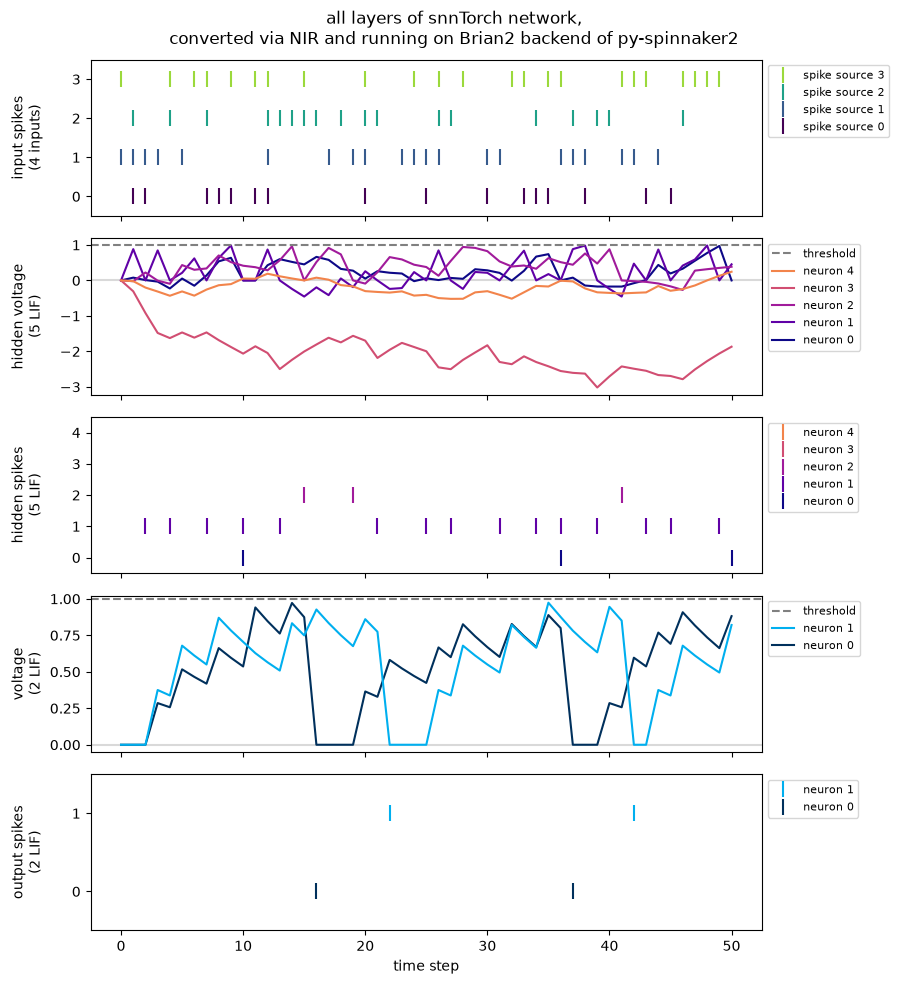

In [7]:
# --- read what we recorded, back in NIR units -------------------------------
v_threshold = 1.0  # snnTorch's default Leaky threshold, in NIR units
hid = hidden[0]  # the single hidden layer (5 LIF); recording switched on in the run cell


def v_in_nir(pop):
    """Membrane voltages of `pop` as {neuron: trace}, rescaled from fixed-point to NIR units."""
    scale = np.broadcast_to(np.atleast_1d(pop.nir_v_scale), (pop.size,))
    return {i: trace / scale[i] for i, trace in pop.get_voltages().items()}


# --- two small plotters, one per panel kind ---------------------------------
LEGEND = dict(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)


def raster(ax, spikes, size, cols, ylabel, prefix="neuron"):
    """One coloured row of spike ticks per neuron."""
    for i in range(size):
        t = spikes.get(i, [])
        ax.plot(t, [i] * len(t), "|", ms=12, mew=1.5, color=cols[i], label=f"{prefix} {i}")
    ax.set(ylabel=ylabel, ylim=(-0.5, size - 0.5), yticks=range(size))
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], **LEGEND)  # highest index first


def voltage(ax, volts, cols, ylabel):
    """Membrane-voltage traces, with the firing threshold and 0 baseline."""
    for i, trace in volts.items():
        ax.plot(trace, color=cols[i], label=f"neuron {i}")
    ax.axhline(v_threshold, ls="--", c="0.5", label="threshold")
    ax.axhline(0, ls="-", c="0.85", zorder=0)
    ax.set(ylabel=ylabel)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], **LEGEND)  # highest index first


# --- one colour set per layer -----------------------------------------------
in_colors = plt.cm.viridis(np.linspace(0, 0.85, input_size))  # inputs
hid_colors = plt.cm.plasma(np.linspace(0, 0.7, hid.size))  # hidden neurons
out_colors = ["#00305C", "#00afef"]  # output neurons
# ----------------------------------------------------------------------------
fig, (ax_in, ax_hv, ax_hs, ax_ov, ax_os) = plt.subplots(5, 1, figsize=(9, 10), sharex=True)

raster(ax_in, input_spikes, input_size, in_colors, "input spikes\n(4 inputs)", prefix="spike source")
voltage(ax_hv, v_in_nir(hid), hid_colors, "hidden voltage\n(5 LIF)")
raster(ax_hs, hid.get_spikes(), hid.size, hid_colors, "hidden spikes\n(5 LIF)")
voltage(ax_ov, v_in_nir(outp[0]), out_colors, "voltage\n(2 LIF)")
raster(ax_os, outp[0].get_spikes(), outp[0].size, out_colors, "output spikes\n(2 LIF)")

ax_os.set_xlabel("time step")
fig.suptitle("all layers of snnTorch network,\nconverted via NIR and running on Brian2 backend of py-spinnaker2")
fig.align_ylabels()
fig.tight_layout()
plt.show()

**What to notice:**

- **This is the snnTorch model itself, running on py-spinnaker2 — nothing was hand-wired.** Every
  population and connection here came out of `from_nir`; the recorded spikes and voltages read back
  exactly like the networks we built by hand in the earlier notebooks.

- **You can follow the forward pass straight down the figure.** Input spikes feed the hidden layer;
  each hidden neuron's voltage integrates and, when it crosses the dashed threshold, emits a spike in
  the panel below it and resets to zero (`reset=ZERO`, matching snnTorch's `Leaky`). Those hidden
  spikes then drive the output layer, which fires the same way.

- **The exact firing pattern is arbitrary — the weights are random.** Hidden neuron 0 gets driven
  steadily negative and never fires, while the output neurons spike regularly; none of that means
  anything here. In a *trained* model these same traces would encode the network's actual computation.


### 3.6 Sanity check: does the conversion match the original?

The whole promise of NIR is that the network on the chip *is* the one you built. Let's check it
directly: run the **original snnTorch model** on the exact same input and lay its spikes over the
py-spinnaker2 output.

Before comparing, account for one thing: **the chip adds a one-step synaptic delay on every
projection** (`conn_delay=0` still leaves that base delay, Section 3.3), whereas snnTorch propagates
through a whole layer within a single tick. The hidden layer is one projection past the input, so we
shift the chip's hidden spikes back by one step to line the two up. The output layer is a second
projection further out (input → hidden → output), so it needs a two-step shift instead. Do that and
**every spike, hidden and output alike, lands on the same step as snnTorch** — the conversion is
exact, since neither layer here carries a bias (`nn.Linear(..., bias=False)`, Section 3.2) that could
drive it independently of its input. With outlier weights or a much bigger, trained model you'd expect
small numeric drift instead of an exact match — which is why a *trained* model is judged by task
accuracy, not tick-by-tick spikes (the accuracy sweep in
<a href="https://spinnaker2.gitlab.io/py-spinnaker2/examples/nir_demo.html">NMNIST with a pre-trained NIR model</a> is the real test).

> **Info**
>
> For a fair comparison the snnTorch model and `cfg.reset` must use the **same** reset rule. Here both reset to zero — `reset_mechanism="zero"` on the `Leaky` layers (Section 3.2) and `cfg.reset = ZERO` (Section 3.3).

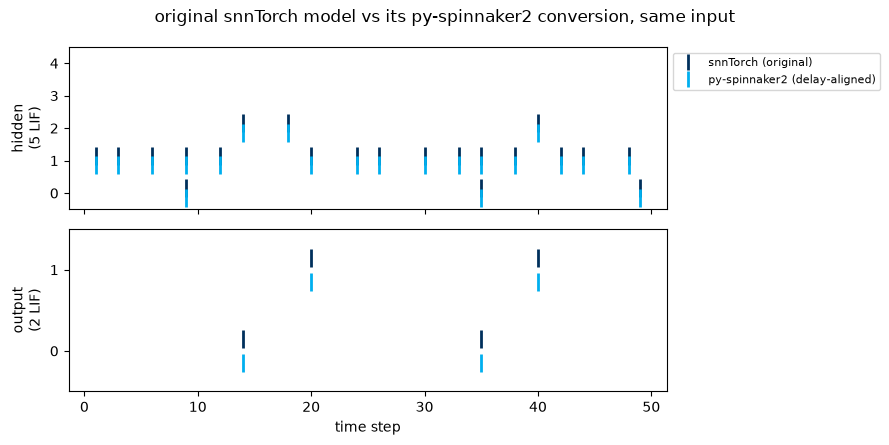

In [8]:
from snntorch import utils

# --- re-run the ORIGINAL snnTorch model on the exact same input --------------
utils.reset(snn_net)  # clear any membrane state left from the export trace
lin1, lif1, lin2, lif2 = snn_net  # nn.Sequential is iterable over its 4 layers

snn_hid = {i: [] for i in range(hid.size)}  # {neuron: spike times}, snnTorch hidden layer
snn_out = {i: [] for i in range(outp[0].size)}  # ...and output layer
for t in range(timesteps):
    x = torch.tensor(input_data[:, t], dtype=torch.float32)  # this step's input (same as the chip)
    spk1 = lif1(lin1(x))  # hidden spikes  (init_hidden -> membrane kept internally)
    spk2, _ = lif2(lin2(spk1))  # output spikes (output=True -> also returns membrane, unused here)
    for i in np.nonzero(spk1.detach().numpy())[0]:
        snn_hid[int(i)].append(t)
    for i in np.nonzero(spk2.detach().numpy())[0]:
        snn_out[int(i)].append(t)


def undelay(spikes, d):
    """Shift chip spikes d steps earlier, undoing the chip's per-projection synaptic delay."""
    return {i: [t - d for t in ts if t - d >= 0] for i, ts in spikes.items()}


# The chip adds one step of synaptic delay per projection.
# The hidden layer sits one projection past the input, so shift it back by 1.
# the output is at distance 2 from the input (input -> hidden -> output), so shift it back by 2.
s2_hid = undelay(hid.get_spikes(), 1)
s2_out = undelay(outp[0].get_spikes(), 2)


# --- overlay snnTorch (original) vs py-spinnaker2 (delay-aligned) -------------
def raster_overlay(ax, ref, s2, size, ylabel):
    """Two rows of ticks per neuron: snnTorch above, py-spinnaker2 below."""
    for i in range(size):
        ax.plot(ref.get(i, []), [i + 0.15] * len(ref.get(i, [])), "|", ms=13, mew=2, color="#00305C")
        ax.plot(s2.get(i, []), [i - 0.15] * len(s2.get(i, [])), "|", ms=13, mew=2, color="#00afef")
    ax.set(ylabel=ylabel, ylim=(-0.5, size - 0.5), yticks=range(size))


fig, (ax_h, ax_o) = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
raster_overlay(ax_h, snn_hid, s2_hid, hid.size, "hidden\n(5 LIF)")
raster_overlay(ax_o, snn_out, s2_out, outp[0].size, "output\n(2 LIF)")
ax_h.plot([], [], "|", color="#00305C", ms=12, mew=2, label="snnTorch (original)")
ax_h.plot([], [], "|", color="#00afef", ms=12, mew=2, label="py-spinnaker2 (delay-aligned)")
ax_h.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
ax_o.set_xlabel("time step")
fig.suptitle("original snnTorch model vs its py-spinnaker2 conversion, same input")
fig.align_ylabels()
fig.tight_layout()
plt.show()

## 4. Scaling up to large trained models

The example above was tiny and untrained, but the workflow doesn't change as the network grows and
carries real trained weights — only a couple of settings start to matter more:

- **`dt` and `integrator` must match your NIR export.** A NIR neuron stores a continuous time constant
  `tau`, and `from_nir` turns it into the chip's per-step decay using `cfg.dt` and `cfg.integrator`
  (the decay depends only on the ratio `dt/tau`). The value to use is the `dt` the *exporter* assumed
  when it encoded `tau` — not a training hyperparameter. snnTorch's `beta` is a dimensionless decay with
  no physical `dt`, so its exporter hardcodes `dt = 1e-4` in `export_nir.py` (`tau = dt/(1-beta)`);
  feeding that same `1e-4` back with `FORWARD` reproduces `beta` exactly. Frameworks with genuine
  physical time constants (Norse, Sinabs) use whatever `dt` they were built with. A mismatch doesn't
  raise; it silently produces wrong dynamics (often neurons that behave as if they have no memory).
  That's why we set `cfg.dt = 1e-4` and `FORWARD` in Section 3.3.
- **Weight scaling.** Big models often have a few outlier weights that waste the chip's integer range.
  Set `cfg.weight_scale_percentile` (e.g. `99`) so scaling is based on a percentile of the weights
  instead of the single maximum.
- **Neurons per core.** Layers with many connections may not fit in one core's memory. Shrink them
  with `pop.set_max_atoms_per_core(...)` after conversion — same mechanism as [05 · Debugging & reading output](./05_debugging.ipynb).

Full details of every `ConversionConfig` field and the neuron-model translation math are in the
[NIR user guide](https://spinnaker2.gitlab.io/py-spinnaker2/user_guide/qs-nir.html). Two worked,
*trained* examples to go further:

- <a href="https://spinnaker2.gitlab.io/py-spinnaker2/examples/nir_demo.html">NMNIST with a pre-trained NIR model</a> — a spiking **CNN** classifying N-MNIST,
  including per-core tuning and an accuracy sweep.
- [`tutorials/nir/end_to_end_deployment/end_to_end_NIR.ipynb`](../nir/end_to_end_deployment/end_to_end_NIR.ipynb)
  — trains an snnTorch model from scratch, exports it to NIR, and deploys it.

The [`examples/nir/`](../../examples/nir) folder has the minimal scripts this notebook is based on
(including a Conv2d variant).

## Recap & what's next

- **NIR** is a portable, framework-neutral SNN graph — train in snnTorch/Norse/Sinabs/etc., export
  one `.nir` file, deploy on SpiNNaker2.
- We exported a small **snnTorch** network to NIR and ran it on SpiNNaker2 in three calls:
  `export_to_nir` (or `nir.read` for a saved model) → `s2_nir.from_nir(graph, cfg)` → `hw.run`.
- `from_nir` returns `(net, inp, outp)`; you set input spikes on `inp` and read spikes/voltages from `outp`.
- `ConversionConfig` controls the float→integer / continuous→discrete translation; `dt` must match the
  source framework's timestep, and `scale_weights` / `max_atoms_per_core` matter most for large models.

**Next up — [09 · Custom neuron models — basics](./09_custom-neuron-models_basics.ipynb)**: going
below the built-in models to write your own neuron dynamics for SpiNNaker2, and how a model is laid
out in a core's memory.